# LSTM y GRU frente a la red recurrente simple (PyTorch)

En la presentación **Memoria de largo plazo: LSTM y GRU** vimos que la red recurrente simple **olvida rápido**: lo que entra a su memoria se va borrando en cada paso, así que le cuesta usar datos que están muchos pasos atrás. Las celdas **LSTM** y **GRU** lo resuelven con **compuertas** que deciden qué guardar, qué olvidar y qué entregar.

Para ver la diferencia necesitamos un problema en el que el dato importante esté **lejos** del final de la ventana. Usamos la temperatura de **Jena** (Alemania), medida **cada 10 minutos** entre 2009 y 2016 por el Instituto Max Planck de Biogeoquímica, y nos preguntamos: **¿qué temperatura hará dentro de 12 horas?**

- La última medición ayuda poco: si ahora es mediodía, dentro de 12 horas será medianoche.
- Lo que más ayuda es saber qué temperatura hizo **ayer a esa misma hora**.

Con una medición cada 10 minutos, un día son 144 pasos y 12 horas son 72 pasos. Si cada ventana tiene 36 horas (216 pasos), la medición de "ayer a esa hora" queda en el paso 216 + 72 − 144 = 144 de la ventana: **72 pasos antes del final**. Para aprovecharla, la red tiene que recordarla durante 72 pasos.

Entrenamos tres redes que solo cambian en la **celda** (RNN, LSTM y GRU), con los mismos datos, el mismo número de neuronas y la misma forma de entrenar. Así cualquier diferencia en el error se debe a la celda. La forma de entrenar es la del notebook anterior; aquí va sin explicación aparte.

## Etapa 1: Se carga la base de datos

In [1]:
import copy
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


Si el archivo no está, se descarga de internet y se descomprime en la carpeta `data`:

In [2]:
data_dir = Path("data")
csv_path = data_dir / "jena_climate_2009_2016.csv"
if not csv_path.exists():
    data_dir.mkdir(exist_ok=True)
    zip_path, _ = urllib.request.urlretrieve("https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip",
                                             data_dir / "jena_climate_2009_2016.csv.zip")
    with zipfile.ZipFile(zip_path) as f:
        f.extract("jena_climate_2009_2016.csv", data_dir)

weather = pd.read_csv(csv_path, usecols=["Date Time", "T (degC)"])
weather["Date Time"] = pd.to_datetime(weather["Date Time"], format="%d.%m.%Y %H:%M:%S")
temperature = weather.drop_duplicates("Date Time").set_index("Date Time")["T (degC)"]  # hay algunas filas repetidas
temperature.head()

Date Time
2009-01-01 00:10:00   -8.02
2009-01-01 00:20:00   -8.41
2009-01-01 00:30:00   -8.51
2009-01-01 00:40:00   -8.31
2009-01-01 00:50:00   -8.27
Name: T (degC), dtype: float64

Una semana de julio de 2015: la temperatura sube de día y baja de noche, y ese ciclo diario se repite cada 144 mediciones.

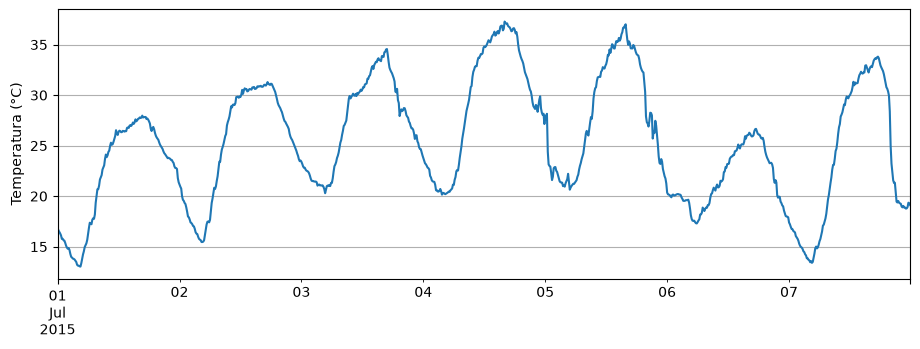

In [3]:
temperature["2015-07-01":"2015-07-07"].plot(figsize=(11, 3.5), grid=True)
plt.xlabel(""); plt.ylabel("Temperatura (°C)")
plt.show()

## Etapa 2: Ventanas

Preparamos los datos como en el notebook anterior, con dos diferencias:

- **La etiqueta está lejos:** ya no es el paso siguiente, sino el que está `horizon = 72` pasos (12 horas) después del final de la ventana.
- **Una ventana por hora:** dos ventanas que empiezan con 10 minutos de diferencia son casi iguales, así que tomamos una cada 6 pasos (`stride=6`). Así el entrenamiento es 6 veces más rápido.

Dividimos en el tiempo (2009 a 2014 para entrenar, 2015 para validar y 2016 para test) y dividimos la temperatura entre 10 para que los valores queden cerca de 1.

In [4]:
class WindowDataset(Dataset):
    def __init__(self, series, window_length, horizon, stride=1):
        self.series = series
        self.window_length = window_length
        self.horizon = horizon
        self.stride = stride

    def __len__(self):
        return (len(self.series) - self.window_length - self.horizon) // self.stride + 1

    def __getitem__(self, idx):
        start = idx * self.stride
        end = start + self.window_length
        window = self.series[start:end].unsqueeze(-1)                      # (T, 1)
        target = self.series[end + self.horizon - 1:end + self.horizon]    # horizon pasos después del final
        return window, target


scale = 10  # dividimos la temperatura entre 10
temp_train = torch.tensor(temperature["2009":"2014"].values / scale, dtype=torch.float32)
temp_valid = torch.tensor(temperature["2015"].values / scale, dtype=torch.float32)
temp_test = torch.tensor(temperature["2016"].values / scale, dtype=torch.float32)

window_length, horizon, day = 216, 72, 144   # 36 horas, 12 horas y un día, en pasos de 10 minutos
train_set = WindowDataset(temp_train, window_length, horizon, stride=6)
valid_set = WindowDataset(temp_valid, window_length, horizon, stride=6)
test_set = WindowDataset(temp_test, window_length, horizon, stride=6)
print("Ventanas de entrenamiento, validación y test:", len(train_set), len(valid_set), len(test_set))

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=256)
test_loader = DataLoader(test_set, batch_size=256)

x, y = next(iter(train_loader))
print("Entrada:", tuple(x.shape), " Etiqueta:", tuple(y.shape))

Ventanas de entrenamiento, validación y test: 52520 8696 8662
Entrada: (64, 216, 1)  Etiqueta: (64, 1)


Cada ejemplo es una pareja **(X, y)**: X son las 216 temperaturas de la ventana, $X = (x_1, \dots, x_{216})$, e y es la temperatura 72 pasos (12 horas) después de $x_{216}$. Cada fila de la tabla es un ejemplo:

In [5]:
def windows_table(dataset, n=5):
    # Una fila por ejemplo: columnas x_1 ... x_T (la entrada X) y la columna y (la etiqueta), en °C
    rows = []
    for i in range(n):
        X, y = dataset[i]
        row = {f"x_{t + 1}": X[t, 0].item() * scale for t in range(len(X))}
        row["y"] = y.item() * scale
        rows.append(row)
    return pd.DataFrame(rows, index=[f"ejemplo {i + 1}" for i in range(n)]).round(1)


with pd.option_context("display.max_columns", 12):
    display(windows_table(train_set))

,x_1,x_2,x_3,x_4,x_5,x_6,...,x_212,x_213,x_214,x_215,x_216,y
ejemplo 1,-8.0,-8.4,-8.5,-8.3,-8.3,-8.1,...,-3.4,-3.2,-3.2,-3.0,-3.1,-4.7
ejemplo 2,-7.6,-7.6,-7.9,-8.4,-8.8,-8.9,...,-2.9,-2.8,-2.8,-2.6,-2.5,-5.3
ejemplo 3,-8.8,-8.8,-8.7,-8.7,-8.7,-8.8,...,-2.5,-2.3,-2.2,-2.4,-2.6,-6.2
ejemplo 4,-8.8,-8.9,-8.9,-8.9,-9.0,-9.0,...,-2.5,-2.1,-2.2,-2.2,-2.1,-6.1
ejemplo 5,-9.2,-9.5,-9.5,-9.4,-9.5,-9.6,...,-2.4,-2.5,-2.5,-2.6,-2.8,-6.2


En la gráfica de un ejemplo de julio de 2010 se ve dónde está el dato que más ayuda: $x_{144}$ (en rojo), la temperatura de un día antes de y, 72 pasos antes del final de la ventana.

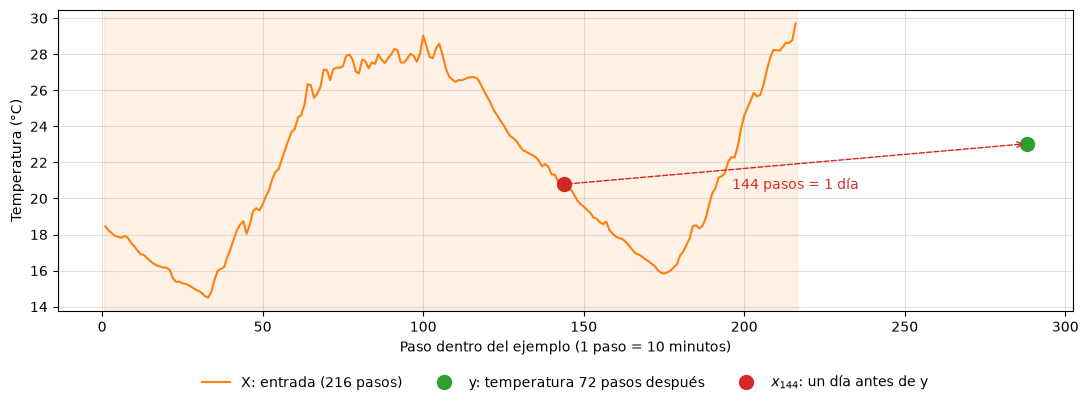

In [6]:
def plot_window(dataset, idx=0):
    X, y = dataset[idx]
    x_vals, y_val = X[:, 0].numpy() * scale, y.item() * scale
    T, H = len(x_vals), dataset.horizon
    key = T + H - day   # posición de "ayer a esa hora" dentro de la ventana

    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.axvspan(0.5, T + 0.5, color="tab:orange", alpha=0.1)
    ax.plot(np.arange(1, T + 1), x_vals, "-", color="tab:orange", label=f"X: entrada ({T} pasos)")
    ax.plot(T + H, y_val, "o", color="tab:green", ms=10, label=f"y: temperatura {H} pasos después")
    ax.plot(key, x_vals[key - 1], "o", color="tab:red", ms=10, label=f"$x_{{{key}}}$: un día antes de y")
    ax.annotate("", xy=(T + H, y_val), xytext=(key, x_vals[key - 1]),
                arrowprops=dict(arrowstyle="->", color="tab:red", ls="--"))
    ax.annotate(f"{day} pasos = 1 día", ((key + T + H) / 2, (x_vals[key - 1] + y_val) / 2), textcoords="offset points",
                xytext=(0, -18), color="tab:red", ha="center")
    ax.set_xlabel("Paso dentro del ejemplo (1 paso = 10 minutos)"); ax.set_ylabel("Temperatura (°C)"); ax.grid(alpha=0.4)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()


# Un ejemplo de verano, cuando el ciclo diario se ve claro (una ventana cada 6 pasos)
july_idx = temperature["2009":"2014"].index.searchsorted(pd.Timestamp("2010-07-01")) // 6
plot_window(train_set, idx=july_idx)

## Etapa 3: Las tres redes, una al lado de la otra

Las tres redes tienen la misma forma: una capa recurrente lee la ventana, tomamos el estado del último paso y una capa densa da el pronóstico. En PyTorch, cambiar de celda es cambiar `nn.RNN` por `nn.LSTM` o `nn.GRU`: reciben los mismos argumentos y la misma entrada `(batch, T, 1)`.

La única diferencia al programarlas está en **lo que devuelven**:

| Celda | Llamada | Qué devuelve además de `outputs` |
|---|---|---|
| RNN | `outputs, h_n = self.rnn(X)` | `h_n`: el último estado oculto |
| GRU | `outputs, h_n = self.gru(X)` | `h_n`: igual que la RNN (la GRU tiene una sola memoria) |
| LSTM | `outputs, (h_n, c_n) = self.lstm(X)` | una **pareja**: el estado oculto `h_n` y el **estado de celda** `c_n`, la memoria de largo plazo que vimos en la presentación |

En los tres casos `outputs` tiene el estado oculto $h_t$ de cada paso, y `outputs[:, -1]` es el resumen de la ventana que va a la capa densa.

In [7]:
class RNNNet(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, h_n = self.rnn(X)            # una sola memoria: h
        return self.head(outputs[:, -1])


class LSTMNet(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, (h_n, c_n) = self.lstm(X)    # dos memorias: h (corto plazo) y c (largo plazo)
        return self.head(outputs[:, -1])


class GRUNet(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, h_n = self.gru(X)            # una sola memoria: h, controlada por compuertas
        return self.head(outputs[:, -1])

Comprobemos lo que devuelve cada capa con un minibatch de ventanas:

In [8]:
x, _ = next(iter(train_loader))
rnn, lstm, gru = RNNNet().rnn, LSTMNet().lstm, GRUNet().gru

outputs, h_n = rnn(x)
print("RNN : outputs", tuple(outputs.shape), " h_n", tuple(h_n.shape))
outputs, (h_n, c_n) = lstm(x)
print("LSTM: outputs", tuple(outputs.shape), " h_n", tuple(h_n.shape), " c_n", tuple(c_n.shape))
outputs, h_n = gru(x)
print("GRU : outputs", tuple(outputs.shape), " h_n", tuple(h_n.shape))

RNN : outputs (64, 216, 32)  h_n (1, 64, 32)
LSTM: outputs (64, 216, 32)  h_n (1, 64, 32)  c_n (1, 64, 32)
GRU : outputs (64, 216, 32)  h_n (1, 64, 32)


Las formas son las mismas; la LSTM solo agrega `c_n`. Lo que sí cambia es **cuántos parámetros** hay dentro de la celda. Como vimos en la presentación, cada compuerta es como una pequeña capa recurrente con sus propios pesos:

- **RNN:** 1 bloque (el cálculo de $h_t$).
- **GRU:** 3 bloques (compuerta de actualización, compuerta de reinicio y el candidato).
- **LSTM:** 4 bloques (compuertas de olvido, de entrada y de salida, y el candidato).

Con las mismas 32 neuronas, la GRU tiene unas 3 veces los parámetros de la RNN y la LSTM unas 4 veces:

In [9]:
NETS = {"RNN": RNNNet, "LSTM": LSTMNet, "GRU": GRUNet}
n_params = {cell: sum(p.numel() for p in net().parameters()) for cell, net in NETS.items()}
for name, n in n_params.items():
    print(f"{name:4s}: {n:5,} parámetros  ({n / n_params['RNN']:.1f} veces la RNN)")

RNN : 1,153 parámetros  (1.0 veces la RNN)
LSTM: 4,513 parámetros  (3.9 veces la RNN)
GRU : 3,393 parámetros  (2.9 veces la RNN)


## Etapa 4: La clase para entrenar

Es la misma organización de la clase `RidershipForecaster` del notebook anterior, con un solo cambio: recibe `cell` (`"RNN"`, `"LSTM"` o `"GRU"`) y con eso arma la red correspondiente del diccionario `NETS`. El MAE se reporta en °C.

In [10]:
class TemperatureForecaster:
    def __init__(self, cell="RNN", hidden_size=32, lr=1e-3):
        # La red se arma dentro de la clase: RNNNet, LSTMNet o GRUNet
        self.net = NETS[cell](hidden_size=hidden_size).to(device)
        self.loss_fn = nn.HuberLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_abs, n = 0.0, 0.0, 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = self.net(X)
            loss = self.loss_fn(y_pred, y)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(X)
            total_abs += (y_pred - y).abs().sum().item()
            n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * scale  # MAE en °C

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_abs, n = 0.0, 0.0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                y_pred = self.net(X)
                total_loss += self.loss_fn(y_pred, y).item() * len(X)
                total_abs += (y_pred - y).abs().sum().item()
                n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * scale

    def fit(self, train_loader, valid_loader, epochs=12):
        best_mae, best_state = float("inf"), None
        start = time.perf_counter()  # medimos cuánto tarda el entrenamiento
        pbar = tqdm(range(epochs), desc="Entrenamiento", unit="época")
        for epoch in pbar:
            loss, mae = self.train_epoch(train_loader)
            val_loss, val_mae = self.evaluate(valid_loader)
            for key, value in zip(self.history, (loss, mae, val_loss, val_mae)):
                self.history[key].append(value)
            if val_mae < best_mae:  # guardamos los mejores pesos
                best_mae, best_state = val_mae, copy.deepcopy(self.net.state_dict())
            pbar.set_postfix(mae=f"{mae:.2f}", val_mae=f"{val_mae:.2f}", mejor_val_mae=f"{best_mae:.2f}")
        self.train_time = time.perf_counter() - start
        self.net.load_state_dict(best_state)  # nos quedamos con los mejores pesos
        print(f"Mejor MAE de validación: {best_mae:.2f} °C  ({self.train_time:.1f} s de entrenamiento)")
        return best_mae

    def predict(self, X):
        # Devuelve el pronóstico (en la escala de entrenamiento) para cada ventana
        self.net.eval()
        with torch.no_grad():
            return self.net(X.to(device)).cpu()

## Etapa 5: Entrenamiento con la misma configuración

Las tres redes se entrenan igual: 32 neuronas, la misma semilla, la misma tasa de aprendizaje y 12 épocas (cada época recorre unas 52 000 ventanas), guardando el mejor modelo según la validación. La clase mide además cuántos segundos tarda cada entrenamiento (`train_time`).

In [11]:
forecasters, val_mae = {}, {}
for cell in NETS:
    print(f"=== {cell} ===")
    torch.manual_seed(42)
    forecasters[cell] = TemperatureForecaster(cell=cell, hidden_size=32)
    val_mae[cell] = forecasters[cell].fit(train_loader, valid_loader, epochs=12)

=== RNN ===


Entrenamiento:   0%|          | 0/12 [00:00<?, ?época/s]

Entrenamiento:   0%|          | 0/12 [00:01<?, ?época/s, mae=4.20, mejor_val_mae=4.24, val_mae=4.24]

Entrenamiento:   8%|▊         | 1/12 [00:01<00:15,  1.40s/época, mae=4.20, mejor_val_mae=4.24, val_mae=4.24]

Entrenamiento:   8%|▊         | 1/12 [00:02<00:15,  1.40s/época, mae=4.02, mejor_val_mae=4.24, val_mae=4.26]

Entrenamiento:  17%|█▋        | 2/12 [00:02<00:12,  1.26s/época, mae=4.02, mejor_val_mae=4.24, val_mae=4.26]

... (72 outputs left out)

Entrenamiento:  92%|█████████▏| 11/12 [00:15<00:01,  1.29s/época, mae=2.23, mejor_val_mae=2.41, val_mae=2.41]

Entrenamiento: 100%|██████████| 12/12 [00:15<00:00,  1.31s/época, mae=2.23, mejor_val_mae=2.41, val_mae=2.41]

Entrenamiento: 100%|██████████| 12/12 [00:15<00:00,  1.32s/época, mae=2.23, mejor_val_mae=2.41, val_mae=2.41]

Mejor MAE de validación: 2.41 °C  (15.8 s de entrenamiento)


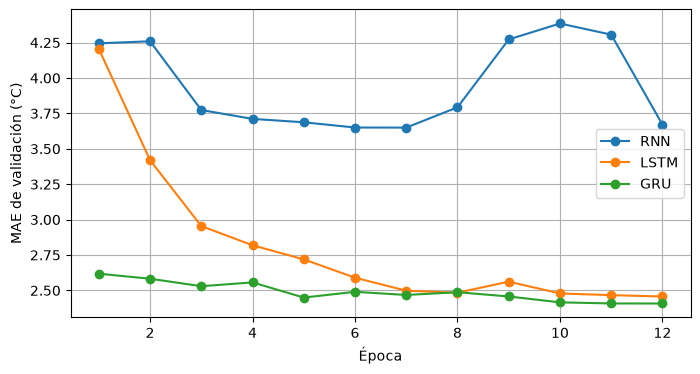

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, forecaster in forecasters.items():
    ax.plot(range(1, len(forecaster.history["val_mae"]) + 1), forecaster.history["val_mae"], "o-", label=name)
ax.set_xlabel("Época"); ax.set_ylabel("MAE de validación (°C)"); ax.grid(); ax.legend()
plt.show()

## Etapa 6: Métricas en el conjunto de test

Medimos las tres redes en **test** (2016), días que ninguna vio, y las ponemos junto a dos **pronósticos ingenuos** como punto de referencia:

- **Último valor:** dentro de 12 horas hará la misma temperatura que ahora ($x_{216}$).
- **Ayer a esa hora:** dentro de 12 horas hará la misma temperatura que un día antes ($x_{144}$).

,parámetros,tiempo de entrenamiento (s),MAE validación (°C),MAE test (°C)
RNN,1153,14.99,3.65,3.37
LSTM,4513,17.03,2.46,2.21
GRU,3393,15.80,2.41,2.13
Ingenuo (último valor),0,0.00,NaN,4.38
Ingenuo (ayer a esa hora),0,0.00,NaN,2.47


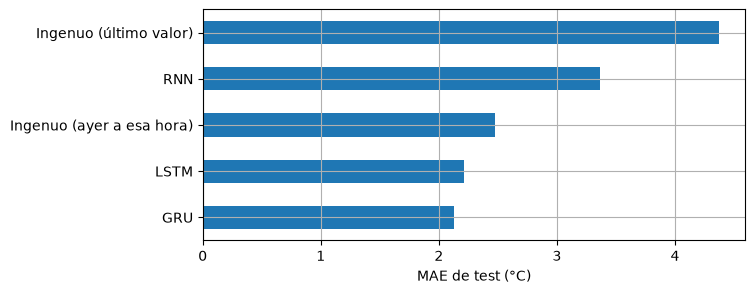

In [13]:
X_test = torch.stack([test_set[i][0] for i in range(len(test_set))])
y_test = torch.stack([test_set[i][1] for i in range(len(test_set))])
key = window_length + horizon - day

naive = {
    "Ingenuo (último valor)": (X_test[:, -1] - y_test).abs().mean().item() * scale,
    "Ingenuo (ayer a esa hora)": (X_test[:, key - 1] - y_test).abs().mean().item() * scale,
}
summary = pd.DataFrame({
    "parámetros": pd.Series(n_params),
    "tiempo de entrenamiento (s)": pd.Series({name: f.train_time for name, f in forecasters.items()}),
    "MAE validación (°C)": pd.Series(val_mae),
    "MAE test (°C)": pd.Series({name: f.evaluate(test_loader)[1] for name, f in forecasters.items()}),
})
for name, mae in naive.items():
    summary.loc[name] = [0, 0, np.nan, mae]
display(summary.round(2))

summary["MAE test (°C)"].sort_values().plot.barh(figsize=(7, 3), grid=True)
plt.xlabel("MAE de test (°C)")
plt.show()

La LSTM y la GRU quedan con un error parecido. Lo que las diferencia es el **costo**: cuántos parámetros tienen y cuánto cálculo hacen.

En la tabla, los tiempos de entrenamiento salen casi iguales. Con redes tan pequeñas, buena parte de ese tiempo se va en armar las ventanas de cada minibatch, que es igual para las tres. Para comparar solo el cálculo de la red, medimos cuánto tarda **un paso de entrenamiento** (pronóstico, `backward` y `step`) con el mismo minibatch, en la CPU y, si hay, en la GPU:

In [14]:
def time_per_step(cell, dev, n_steps=20):
    # Milisegundos que tarda un paso de entrenamiento de la red con un minibatch
    net = NETS[cell]().to(dev)
    optimizer = torch.optim.Adam(net.parameters())
    X, y = next(iter(train_loader))
    X, y = X.to(dev), y.to(dev)

    def step():
        loss = nn.functional.huber_loss(net(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    for _ in range(3):  # calentamiento: los primeros pasos son más lentos
        step()
    if dev == "cuda":
        torch.cuda.synchronize()  # la GPU trabaja en paralelo: esperamos a que termine
    start = time.perf_counter()
    for _ in range(n_steps):
        step()
    if dev == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / n_steps * 1000


devices = ["cpu"] + (["cuda"] if torch.cuda.is_available() else [])
for dev in devices:
    summary[f"ms por paso ({dev.upper()})"] = pd.Series({cell: time_per_step(cell, dev) for cell in NETS})
display(summary.loc[list(NETS)].round(2))

,parámetros,tiempo de entrenamiento (s),MAE validación (°C),MAE test (°C),ms por paso (CPU),ms por paso (CUDA)
RNN,1153,14.99,3.65,3.37,12.60,0.74
LSTM,4513,17.03,2.46,2.21,39.38,0.77
GRU,3393,15.80,2.41,2.13,51.02,0.79


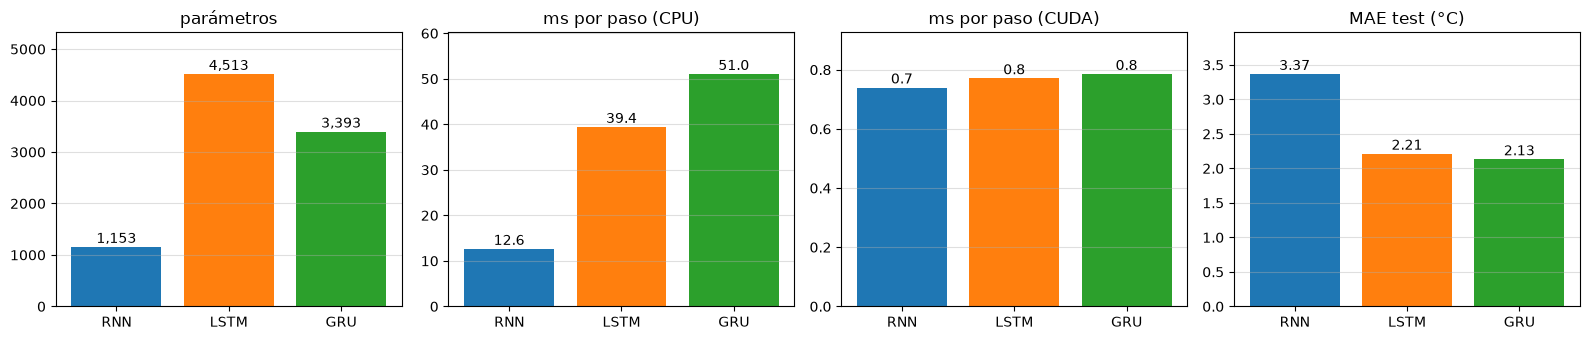

In [15]:
cells = list(NETS)
columns = ["parámetros"] + [f"ms por paso ({dev.upper()})" for dev in devices] + ["MAE test (°C)"]
fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 3.5))
for ax, column in zip(axes, columns):
    values = summary.loc[cells, column]
    ax.bar(cells, values, color=["tab:blue", "tab:orange", "tab:green"])
    for k, v in enumerate(values):
        ax.annotate(f"{v:,.0f}" if column == "parámetros" else f"{v:.2f}" if "MAE" in column else f"{v:.1f}",
                    (k, v), textcoords="offset points", xytext=(0, 3), ha="center")
    ax.set_title(column); ax.grid(axis="y", alpha=0.4); ax.set_ylim(0, values.max() * 1.18)
plt.tight_layout()
plt.show()

Algunas cosas para observar (los números exactos cambian un poco en cada ejecución):

- La **RNN** queda **peor que el ingenuo "ayer a esa hora"**: no logra usar la medición de hace 72 pasos, porque al llegar al final de la ventana ya la olvidó. Es lo que vimos en la presentación: lo que entra a la memoria de la RNN se va borrando en cada paso.
- En la curva de validación, la RNN se queda estancada lejos de las otras dos y su error sube y baja de una época a otra: es el síntoma de los gradientes que se desvanecen o explotan al recorrer 216 pasos hacia atrás.
- La **LSTM** y la **GRU** sí le ganan a ese ingenuo: sus compuertas les permiten guardar lo importante durante los 72 pasos.
- La **GRU** queda a la altura de la **LSTM** (a veces un poco mejor, a veces un poco peor) con unos **25 % menos de parámetros** (3 bloques en vez de 4): ocupa menos memoria y tiene menos pesos que ajustar.
- En **tiempo**, la RNN, con un solo bloque, es claramente la más rápida en la CPU. Entre la LSTM y la GRU los tiempos son parecidos y cambian de una ejecución a otra: la GRU hace menos cálculos, pero el tiempo real también depende de cómo esté programada cada celda en PyTorch. En la GPU los bloques se calculan en paralelo y, con redes tan pequeñas, las tres tardan casi lo mismo.
- Por eso la GRU es una buena primera opción: el mismo error que la LSTM con menos parámetros. La LSTM vale la pena probarla cuando hay muchos datos y la GRU se queda corta.

Finalmente, los pronósticos de las tres redes durante cinco días de julio de 2016, en test (una ventana por hora):

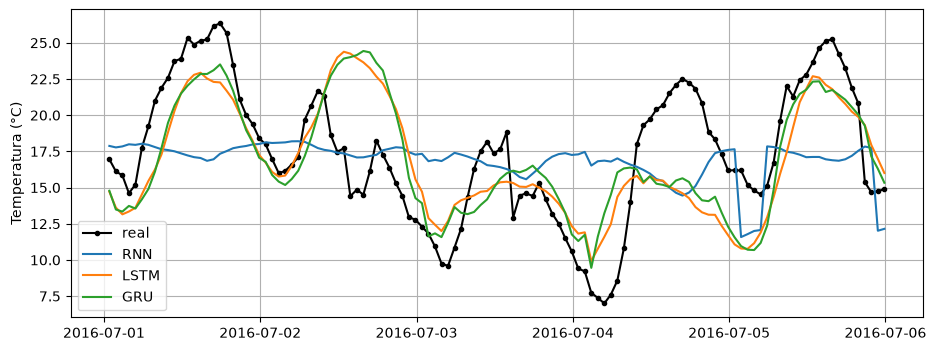

In [16]:
n_hours = 5 * 24
# Fecha de la etiqueta de cada ventana de test (una ventana por hora)
target_times = temperature["2016"].index[window_length + horizon - 1::6][:len(test_set)]
start = target_times.searchsorted(pd.Timestamp("2016-07-01"))
hours = slice(start, start + n_hours)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(target_times[hours], y_test[hours, 0] * scale, "k.-", label="real")
for name in forecasters:
    y_pred = forecasters[name].predict(X_test[hours]).squeeze() * scale
    ax.plot(target_times[hours], y_pred, label=name)
ax.set_ylabel("Temperatura (°C)"); ax.grid(); ax.legend()
plt.show()

La RNN pronostica casi una línea plana, cerca del promedio: como ya olvidó cómo fue el día anterior, no sabe si dentro de 12 horas será de día o de noche. La LSTM y la GRU siguen la subida y la bajada de cada día.

**¿Siempre hace falta una LSTM o una GRU?** No. Cuando el dato que más sirve está cerca del final de la ventana, como en el metro del notebook anterior (el mismo día de la semana pasada, 7 pasos atrás), la RNN simple todavía lo recuerda y las tres celdas dan casi lo mismo. Las compuertas marcan la diferencia cuando hay que recordar algo de muchos pasos atrás.

En el siguiente notebook volvemos al metro y usamos la GRU para pronosticar **varios días hacia adelante**.